In [1]:
import pandas as pd
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv("IMDB Dataset.csv")
print(df.head())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [3]:
tokenized_documents = df['review'].apply(simple_preprocess).tolist()

In [4]:
model = Word2Vec(sentences=tokenized_documents, vector_size=100, window=5, min_count=2, workers=4)
word_vectors = model.wv
words = list(word_vectors.index_to_key)
vectors = [word_vectors[word] for word in words]

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


In [5]:
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(vectors)
clusters = kmeans.labels_
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(vectors)

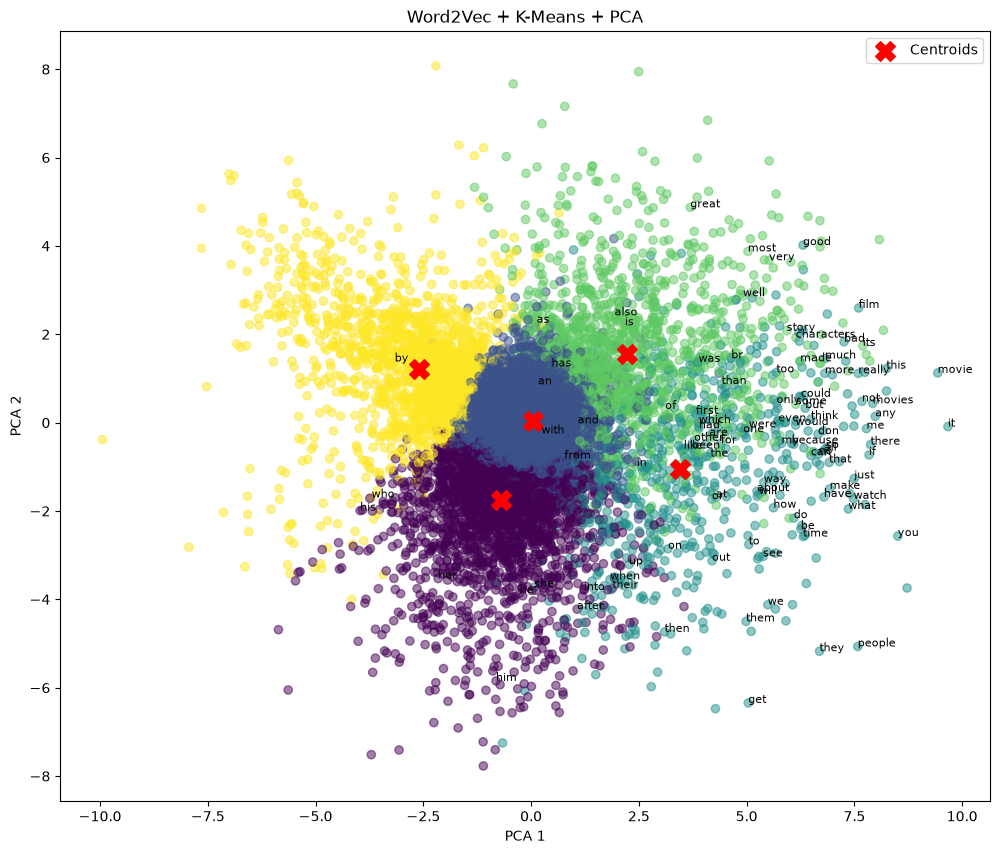

In [6]:
plt.figure(figsize=(12, 10))

plt.scatter(
    reduced_vectors[:, 0],
    reduced_vectors[:, 1],
    c=clusters,
    cmap='viridis',
    alpha=0.5
)

centers = pca.transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    marker='X',
    label='Centroids'
)
for i, word in enumerate(words[:100]):
    plt.annotate(
        word,
        (reduced_vectors[i, 0], reduced_vectors[i, 1]),
        fontsize=8
    )

plt.title("Word2Vec + K-Means + PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()

plt.show()

In [8]:
print("Most similar to 'good':")
print(model.wv.most_similar("good", topn=10))

print("\nMost similar to 'bad':")
print(model.wv.most_similar("bad", topn=10))

print("\nMost similar to 'movie':")
print(model.wv.most_similar("movie", topn=10))

print("\nSimilarity between 'good' and 'great':")
print(model.wv.similarity("good", "great"))

print("\nSimilarity between 'good' and 'terrible':")
print(model.wv.similarity("good", "terrible"))

Most similar to 'good':
[('bad', 0.776742696762085), ('great', 0.7513009309768677), ('decent', 0.7475131154060364), ('cool', 0.6938068270683289), ('nice', 0.6907576322555542), ('fine', 0.6627427339553833), ('lousy', 0.6291297078132629), ('solid', 0.6130247712135315), ('funny', 0.6067321300506592), ('alright', 0.5972092747688293)]

Most similar to 'bad':
[('good', 0.7767427563667297), ('terrible', 0.7682350873947144), ('awful', 0.7515035271644592), ('horrible', 0.7391132712364197), ('lousy', 0.7130820751190186), ('stupid', 0.7103492617607117), ('lame', 0.7035528421401978), ('cheesy', 0.6586914658546448), ('poor', 0.6363685131072998), ('dumb', 0.6338293552398682)]

Most similar to 'movie':
[('film', 0.9246670603752136), ('flick', 0.749969482421875), ('it', 0.6813519597053528), ('show', 0.6425167322158813), ('documentary', 0.6305752992630005), ('movies', 0.6202950477600098), ('picture', 0.6153810620307922), ('sequel', 0.586215615272522), ('series', 0.5808039903640747), ('thing', 0.5696545

In [9]:
model.wv.most_similar(
    positive=["good", "movie"],
    negative=["bad"],
    topn=10
)

[('film', 0.8087076544761658),
 ('flick', 0.6187968850135803),
 ('it', 0.5830461978912354),
 ('show', 0.5637755393981934),
 ('documentary', 0.5586709380149841),
 ('picture', 0.5584478378295898),
 ('series', 0.5447196364402771),
 ('entertainment', 0.5157139301300049),
 ('movies', 0.5113101601600647),
 ('entertaining', 0.49195724725723267)]